# Friendship Network Analysis Using Graph Theory

## Project Overview

This project analyzes a student friendship network using graph theory and NetworkX.

### Objectives
- Construct a friendship network as an undirected graph.
- Measure network structure using degree, betweenness, and closeness centrality.
- Analyze density, diameter, and clustering.
- Detect communities using the Louvain method.
- Use PageRank to identify structurally important nodes.
- Visualize the overall friendship network.

### Tools
- Python
- Pandas
- NetworkX
- Matplotlib
- python-louvain

> **Note:** The dataset represents a specific friendship network. The results describe the structure of this dataset and should not be interpreted as general conclusions about students or friendships.

In [1]:
# Required packages
# Install these once in your Python environment if they are not already available.
#
# pip install pandas networkx matplotlib python-louvain
#
# The project also includes a requirements.txt file for reproducible setup.

In [11]:
%pip install python-louvain

  Using cached python-louvain-0.16.tar.gz (204 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for python-louvain: filename=python_louvain-0.16-py3-none-any.whl size=9458 sha256=24410880443d5e876cd6d20314170b1dafe3386a6f5526b3c0b7f0ec0c1e7d69
  Stored in directory: /Users/sahasra/Library/Caches/pip/wheels/ae/22/72/95110a1ec427d179bc90c8ae1bcf245568db417ac2f34dee63
Successfully built python-louvain
Note: you may need to restart the kernel to use updated packages.


## 1. Graph Construction

In [12]:
import pandas as pd
import networkx as nx

DATA_FILE = "friendship_network.csv"

df = pd.read_csv(DATA_FILE)

required_columns = {"Name", "Friends"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

edges = []

for _, row in df.iterrows():
    person = str(row["Name"]).strip()
    friends = str(row["Friends"]).split(",")

    for friend in friends:
        friend = friend.strip()
        if person and friend and friend != person:
            edges.append((person, friend))

G = nx.Graph()
G.add_edges_from(edges)

print(f"Nodes: {G.number_of_nodes()}")
print(f"Edges: {G.number_of_edges()}")

Nodes: 43
Edges: 239


🔍 Insight:

Each student is a node

Each friendship forms a connection

The resulting graph models real social interactions

## 2. Basic Network Properties

In [13]:
network_properties = {
    "Number of nodes": G.number_of_nodes(),
    "Number of edges": G.number_of_edges(),
    "Network density": nx.density(G),
    "Connected": nx.is_connected(G),
}

for metric, value in network_properties.items():
    print(f"{metric}: {value}")

Number of nodes: 43
Number of edges: 239
Network density: 0.2646733111849391
Connected: True


## 3. Degree Centrality

In [4]:
degree_centrality = nx.degree_centrality(G)

for node, value in degree_centrality.items():
    print(f"{node}: {value:.4f}")



Student_01: 0.1190
Student_02: 1.0000
Student_03: 0.2143
Student_04: 0.3810
Student_05: 0.1667
Student_06: 0.1905
Student_07: 0.1667
Student_08: 0.2381
Student_09: 0.2381
Student_10: 0.2143
Student_11: 0.1429
Student_12: 0.2619
Student_13: 0.2619
Student_14: 0.1429
Student_15: 0.2143
Student_16: 0.1190
Student_17: 0.1429
Student_18: 0.1905
Student_19: 0.2381
Student_20: 0.3571
Student_21: 0.2143
Student_22: 0.5714
Student_23: 0.4286
Student_24: 0.2143
Student_25: 0.2143
Student_26: 0.1667
Student_27: 0.4048
Student_28: 0.3095
Student_29: 0.3810
Student_30: 0.2857
Student_31: 0.1905
Student_32: 0.3333
Student_33: 0.3095
Student_34: 0.2619
Student_35: 0.2143
Student_36: 0.3095
Student_37: 0.2143
Student_38: 0.2143
Student_39: 0.2143
Student_40: 0.2381
Student_41: 0.2381
Student_42: 0.2143
Student_43: 0.2381


### Interpretation

**What does this result mean?**

Degree centrality measures the proportion of other nodes directly connected to each student.

**What does it say about this dataset?**

Students with higher degree centrality have more direct connections within this network. It describes direct connectivity, not overall influence or popularity.

## 4. Betweenness Centrality

In [14]:
betweenness_centrality = nx.betweenness_centrality(G)

for node, value in betweenness_centrality.items():
    print(f"{node}: {value:.4f}")



Student_01: 0.0000
Student_02: 0.4437
Student_03: 0.0040
Student_04: 0.0273
Student_05: 0.0028
Student_06: 0.0047
Student_07: 0.0002
Student_08: 0.0068
Student_09: 0.0044
Student_10: 0.0033
Student_11: 0.0000
Student_12: 0.0076
Student_13: 0.0078
Student_14: 0.0007
Student_15: 0.0073
Student_16: 0.0002
Student_17: 0.0010
Student_18: 0.0039
Student_19: 0.0053
Student_20: 0.0156
Student_21: 0.0005
Student_22: 0.0710
Student_23: 0.0232
Student_24: 0.0009
Student_25: 0.0039
Student_26: 0.0005
Student_27: 0.0172
Student_28: 0.0050
Student_29: 0.0151
Student_30: 0.0122
Student_31: 0.0014
Student_32: 0.0139
Student_33: 0.0085
Student_34: 0.0079
Student_35: 0.0007
Student_36: 0.0144
Student_37: 0.0062
Student_38: 0.0052
Student_39: 0.0006
Student_40: 0.0022
Student_41: 0.0046
Student_42: 0.0018
Student_43: 0.0079


### Interpretation

**What does this result mean?**

Betweenness centrality measures how often a node lies on shortest paths between other nodes.

**What does it say about this dataset?**

Nodes with higher betweenness centrality can occupy bridge-like positions between different parts of the network.

## 5. Closeness Centrality

In [15]:
closeness_centrality = nx.closeness_centrality(G)

for node, value in closeness_centrality.items():
    print(f"{node}: {value:.4f}")



Student_01: 0.5316
Student_02: 1.0000
Student_03: 0.5600
Student_04: 0.6176
Student_05: 0.5455
Student_06: 0.5526
Student_07: 0.5455
Student_08: 0.5676
Student_09: 0.5676
Student_10: 0.5600
Student_11: 0.5385
Student_12: 0.5753
Student_13: 0.5753
Student_14: 0.5385
Student_15: 0.5600
Student_16: 0.5316
Student_17: 0.5385
Student_18: 0.5526
Student_19: 0.5676
Student_20: 0.6087
Student_21: 0.5600
Student_22: 0.7000
Student_23: 0.6364
Student_24: 0.5600
Student_25: 0.5600
Student_26: 0.5455
Student_27: 0.6269
Student_28: 0.5915
Student_29: 0.6176
Student_30: 0.5833
Student_31: 0.5526
Student_32: 0.6000
Student_33: 0.5915
Student_34: 0.5753
Student_35: 0.5600
Student_36: 0.5915
Student_37: 0.5600
Student_38: 0.5600
Student_39: 0.5600
Student_40: 0.5676
Student_41: 0.5676
Student_42: 0.5600
Student_43: 0.5676


### Interpretation

**What does this result mean?**

Closeness centrality measures how close a node is to all other nodes based on shortest-path distances.

**What does it say about this dataset?**

Nodes with higher closeness centrality can reach the rest of the connected network through relatively short paths.

## 6. Network Density

In [16]:
density = nx.density(G)
print("Network Density:", density)


Network Density: 0.2646733111849391


### Interpretation

**What does this result mean?**

Network density is the proportion of observed edges relative to all possible edges in a simple undirected graph.

**Observed value:** approximately **0.265**.

This means that about 26.5% of all possible pairwise connections are present in this dataset.

## 7. Network Diameter

In [17]:
if nx.is_connected(G):
    diameter = nx.diameter(G)
    print("Network Diameter:", diameter)
else:
    print("Graph is not connected, diameter not defined.")


Network Diameter: 2


### Interpretation

**What does this result mean?**

Network diameter is the longest shortest-path distance between any two nodes.

**Observed value:** **2**.

Therefore, the most distant pair of students in this connected graph is separated by two friendship-network steps.

## 8. Clustering Coefficient

In [18]:
clustering_coeff = nx.average_clustering(G)
print("Average Clustering Coefficient:", clustering_coeff)



Average Clustering Coefficient: 0.6531124864814097


### Interpretation

**What does this result mean?**

The average clustering coefficient measures the tendency of connected neighbors of a node to also be connected to one another.

**Observed value:** approximately **0.653**.

This indicates substantial local clustering in this particular friendship network.

## 9. Community Detection

In [19]:
import community as community_louvain

partition = community_louvain.best_partition(G, random_state=42)

communities = {}
for node, community_id in partition.items():
    communities.setdefault(community_id, set()).add(node)

sorted_comm = sorted(communities.values(), key=len, reverse=True)

print("--- Community Detection Analysis ---")
print(f"Total Communities Found: {len(sorted_comm)}\n")

for i, comm_nodes in enumerate(sorted_comm, start=1):
    sub = G.subgraph(comm_nodes)
    dens = nx.density(sub)
    print(f"Community {i}: {len(comm_nodes)} members | Density: {dens:.2f}")

print("\nLargest community members:")
print(sorted(sorted_comm[0]))

print("\nSmallest community members:")
print(sorted(sorted_comm[-1]))

--- Community Detection Analysis ---
Total Communities Found: 4

Community 1: 13 members | Density: 0.46
Community 2: 11 members | Density: 0.75
Community 3: 10 members | Density: 0.84
Community 4: 9 members | Density: 0.75

Largest community members:
['Student_01', 'Student_03', 'Student_04', 'Student_05', 'Student_06', 'Student_16', 'Student_17', 'Student_18', 'Student_19', 'Student_36', 'Student_41', 'Student_42', 'Student_43']

Smallest community members:
['Student_22', 'Student_26', 'Student_28', 'Student_31', 'Student_32', 'Student_33', 'Student_38', 'Student_39', 'Student_40']


## 10. PageRank

PageRank assigns an importance score to each node based on the structure of its connections. In this project, it is used as a network-structure measure rather than a direct measure of personal popularity.

In [20]:
pagerank = nx.pagerank(G)

pagerank_df = (
    pd.DataFrame(
        sorted(pagerank.items(), key=lambda x: x[1], reverse=True),
        columns=["Student", "PageRank"]
    )
)

print("Top 5 nodes by PageRank:")
print(pagerank_df.head(5).to_string(index=False))

print("\nBottom 5 nodes by PageRank:")
print(pagerank_df.tail(5).sort_values("PageRank").to_string(index=False))

Top 5 nodes by PageRank:
   Student  PageRank
Student_02  0.080474
Student_22  0.046135
Student_23  0.034469
Student_04  0.033064
Student_27  0.032806

Bottom 5 nodes by PageRank:
   Student  PageRank
Student_01  0.012715
Student_16  0.012740
Student_14  0.014265
Student_17  0.014533
Student_11  0.014656


### Top 5 Nodes by PageRank

In [21]:
pagerank_df.head(5)

,Student,PageRank
0,Student_02,0.080474
1,Student_22,0.046135
2,Student_23,0.034469
3,Student_04,0.033064
4,Student_27,0.032806


### Bottom 5 Nodes by PageRank

In [22]:
pagerank_df.sort_values(by="PageRank", ascending=True).head(5)

,Student,PageRank
42,Student_01,0.012715
41,Student_16,0.012740
40,Student_14,0.014265
39,Student_17,0.014533
38,Student_11,0.014656


## 11. Network Visualization

## 12. Key Findings

Based on the current dataset:

- **Nodes:** 43
- **Edges:** 239
- **Network density:** approximately 0.265
- **Network diameter:** 2
- **Average clustering coefficient:** approximately 0.653
- **Detected communities:** 4

The network is connected, has a short diameter, and shows noticeable local clustering. Community detection also reveals several groups of densely connected nodes. Centrality measures and PageRank provide different structural perspectives, so they should not be treated as interchangeable measures.

## Conclusion

This analysis demonstrates how graph-based methods can be used to study the structure of a friendship network. Degree centrality describes direct connectivity, betweenness highlights bridge positions, closeness captures network proximity, community detection identifies groups, and PageRank provides another measure of structural importance.

The findings are specific to the supplied dataset and should be interpreted as a network analysis rather than as a judgment about the individuals represented by the nodes.

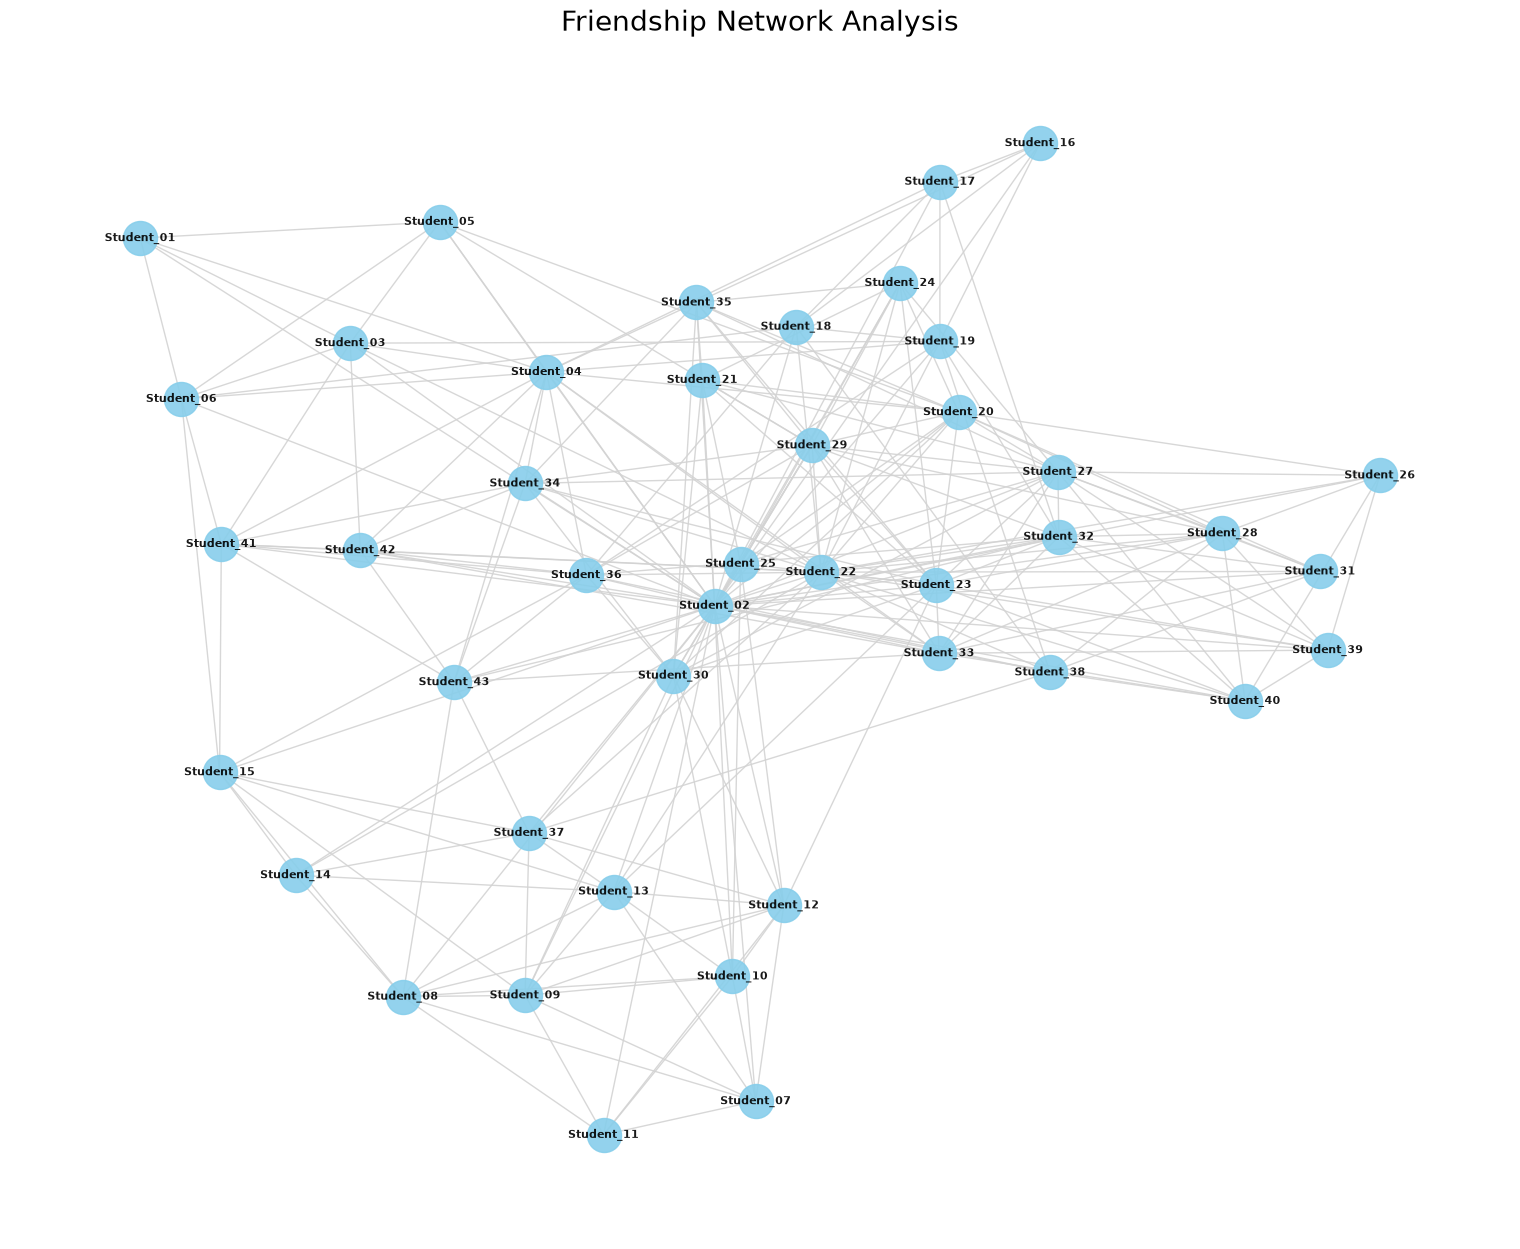

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 12))

pos = nx.spring_layout(G, k=0.5, iterations=50, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=600,
    node_color="skyblue",
    edge_color="lightgray",
    font_size=8,
    font_weight="bold",
    alpha=0.9,
)

plt.title("Friendship Network Analysis", fontsize=20)
plt.axis("off")
plt.savefig("friendship_graph.png", dpi=300, bbox_inches="tight")
plt.show()

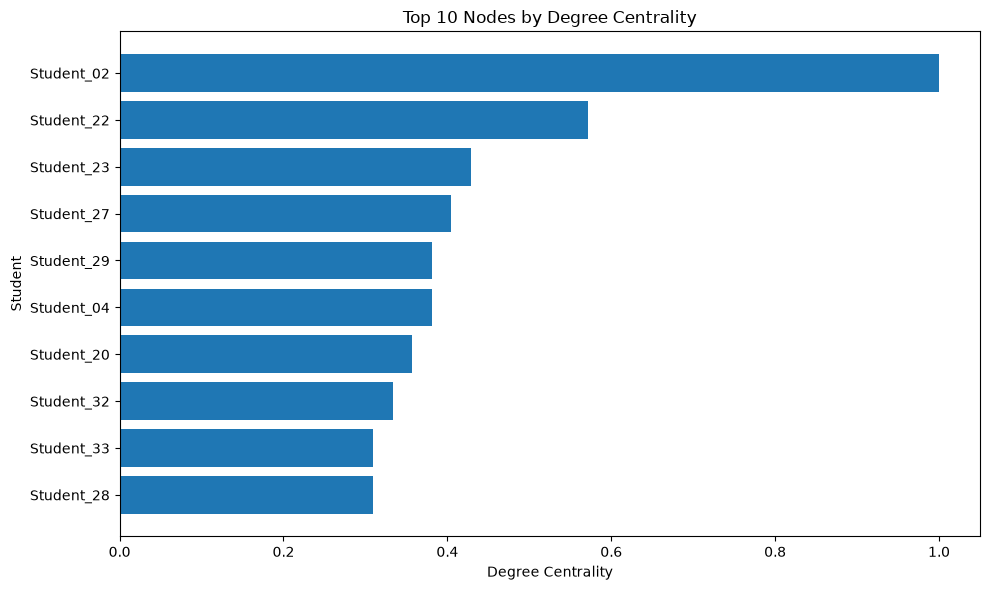

In [24]:
# Compare the top 10 nodes by degree centrality

degree_df = (
    pd.DataFrame(
        degree_centrality.items(),
        columns=["Student", "DegreeCentrality"]
    )
    .sort_values("DegreeCentrality", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
plt.barh(degree_df["Student"][::-1], degree_df["DegreeCentrality"][::-1])
plt.xlabel("Degree Centrality")
plt.ylabel("Student")
plt.title("Top 10 Nodes by Degree Centrality")
plt.tight_layout()
plt.show()